# Sequential models: from AR to ARX to an RNN

<a target="_blank" href="https://colab.research.google.com/github/changyaochen/MECE4520/blob/master/site/sequential-models/02-silverbox-arx-rnn.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

The [Silverbox benchmark](https://www.nonlinearbenchmark.org/benchmarks/silverbox) records the response of an electronic system designed to behave like a Duffing oscillator. It provides one deliberately applied input, `V1`, and one measured response, `V2`. A useful mechanical analogy is a force-like excitation $u_t$ and a displacement-like response $y_t$.

The samples are synchronized. In the discrete-time models below, the response at time $t$ may depend on the imposed input $u_t$, earlier input values, and the system's earlier responses. This expresses a physically plausible causal direction—input to response—without assuming that every effect is instantaneous.

We will predict the next response using information available at that time. The main comparison uses past responses only, past responses plus the known input, or a learned nonlinear recurrent state representation.

## What you will do

1. Load one real input--response system-identification benchmark.
2. Preserve its chronological training/test experiment split.
3. Fit an AR(20) model using only past response values.
4. Add the known forcing signal to create an ARX(20) model.
5. Fit a small RNN that can learn a nonlinear representation of a recent input--response sequence.
6. Compare the AR, ARX, and RNN models using a recursive multi-step held-out forecast.
7. *(Optional)* Swap the RNN cell for an LSTM while keeping the sequence and scoring protocol fixed.

## 1. Load the measured input--response experiments

The `nonlinear-benchmarks` package downloads the official Silverbox record to the notebook runtime. Nothing is fitted to the held-out experiment.

In [1]:
# This package downloads the official Silverbox benchmark when it is first used.
try:
    from nonlinear_benchmarks import Silverbox
except ModuleNotFoundError:
    %pip install -q nonlinear-benchmarks
    from nonlinear_benchmarks import Silverbox

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_SEED = 7
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# Prefer an NVIDIA GPU (CUDA), then an Apple Silicon GPU (MPS), then the CPU.
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"PyTorch device: {device}")

PyTorch device: mps


In [2]:
# Store the official download in the notebook's local working directory.
# In Colab, this directory is temporary and disappears when the runtime ends.
benchmark_directory = Path("silverbox-data")
benchmark_directory.mkdir(exist_ok=True)
training_record, test_records = Silverbox(dir_placement=benchmark_directory)
test_record = test_records[0]  # The official held-out multisine experiment.

u_train = np.asarray(training_record.u, dtype=float).reshape(-1)
y_train = np.asarray(training_record.y, dtype=float).reshape(-1)
u_test = np.asarray(test_record.u, dtype=float).reshape(-1)
y_test = np.asarray(test_record.y, dtype=float).reshape(-1)
sampling_time = float(training_record.sampling_time)

print(f"Training samples: {len(y_train):,}")
print(f"Held-out samples: {len(y_test):,}")
print(f"Sampling interval: {sampling_time * 1_000:.4f} ms")

dataset not found downloading from https://drive.google.com/file/d/17iS-6oBUUgrmiAcrZoG9S5sOaljZnDSy/view 
 in silverbox-data/Silverbox/SilverboxFiles.zip


extracting file...
save_loc='silverbox-data/Silverbox/SilverboxFiles.zip'
Training samples: 65,062
Held-out samples: 21,688
Sampling interval: 1.6384 ms


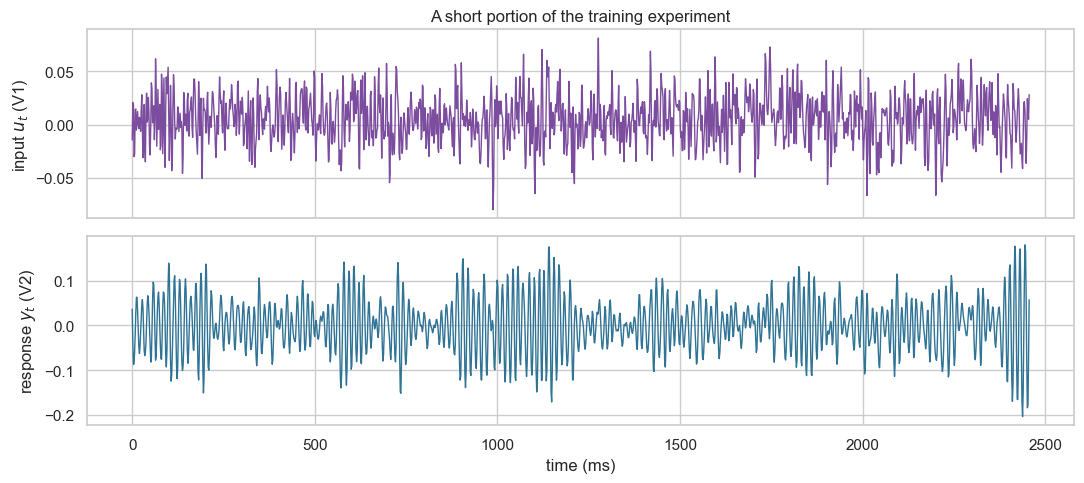

In [3]:
display_samples = 1_500
time_ms = np.arange(display_samples) * sampling_time * 1_000

fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axes[0].plot(time_ms, u_train[:display_samples], color="#7c4d9e", linewidth=1)
axes[0].set(ylabel="input $u_t$ (V1)", title="A short portion of the training experiment")
axes[1].plot(time_ms, y_train[:display_samples], color="#2f7395", linewidth=1)
axes[1].set(xlabel="time (ms)", ylabel="response $y_t$ (V2)")
plt.tight_layout()
plt.show()

## 2. Set up one forecasting protocol

An **autoregressive (AR)** model forecasts a response from its own past values. An **autoregressive model with exogenous input (ARX)** extends that idea by adding one or more external signals that are available at prediction time. Such an input might be a commanded actuator signal, an ambient measurement, or a known operating schedule; it is *exogenous* because it is supplied from outside the response's own history.

Here, `V1` is the exogenous input and `V2` is the response. We will first apply the AR technique to forecast `V2` purely from its past `V2` values. Next, we will add the known applied input `V1`. Finally, we will fit a small RNN that can learn a nonlinear relationship from a recent input--response history.

There are two useful forecasting protocols:

- **One-step-ahead forecasting (observed lags):** use the actual preceding `V2` measurements at every time step.
- **Recursive multi-step forecasting (predicted lags):** after an initial window, reuse each prediction as a lagged `V2` input for later predictions.

We use recursive multi-step forecasting throughout this notebook. Every model uses the first $p=20$ measured responses in the held-out experiment only to initialize its state. Afterwards, later true `V2` responses are **not** fed back to the model.

The applied input $u_t$ remains known throughout the held-out experiment. That is natural in system identification: it is an externally imposed forcing signal, not an unknown future response measurement.

For this example, the two linear models are

$$
\begin{aligned}
\text{AR}(p):\quad \widehat{y}_t &= \beta_0 + \sum_{j=1}^{p}\beta_j y_{t-j},\\
\text{ARX}(p):\quad \widehat{y}_t &= \beta_0 + \sum_{j=1}^{p}\beta_j y_{t-j} + \sum_{j=0}^{p}\gamma_j u_{t-j}.
\end{aligned}
$$

In [4]:
ORDER = 20


def make_linear_design(
    *,
    input_signal: np.ndarray,
    output_signal: np.ndarray,
    order: int,
    include_input: bool,
) -> tuple[np.ndarray, np.ndarray]:
    """Build one-step input rows for an AR or ARX model.

    Args:
        input_signal: Known forcing values $u_t$ from one experiment.
        output_signal: Measured response values $y_t$ from one experiment.
        order: Number of earlier response values to include.
        include_input: Whether to append the current and lagged input values.

    Returns:
        A feature matrix and matching next-response target vector.
    """
    rows: list[np.ndarray] = []
    targets: list[float] = []
    for index in range(order, len(output_signal)):
        response_lags = output_signal[index - order : index][::-1]
        if include_input:
            input_lags = input_signal[index - order : index + 1][::-1]
            rows.append(np.concatenate((response_lags, input_lags)))
        else:
            rows.append(response_lags)
        targets.append(output_signal[index])
    return np.asarray(rows), np.asarray(targets)


def fit_linear_forecaster(
    *,
    input_signal: np.ndarray,
    output_signal: np.ndarray,
    order: int,
    include_input: bool,
) -> tuple[StandardScaler, LinearRegression]:
    """Fit a linear AR or ARX forecaster.

    Args:
        input_signal: Known forcing values from the training experiment.
        output_signal: Measured training responses.
        order: Number of earlier response values to use.
        include_input: Whether to fit an ARX model instead of an AR model.

    Returns:
        The training-only feature scaler and fitted linear model.
    """
    features, targets = make_linear_design(
        input_signal=input_signal,
        output_signal=output_signal,
        order=order,
        include_input=include_input,
    )
    # Fit the scaler on training rows only, then fit ordinary least squares.
    scaler = StandardScaler().fit(features)
    model = LinearRegression().fit(scaler.transform(features), targets)
    return scaler, model


def recursive_linear_forecast(
    *,
    input_signal: np.ndarray,
    observed_output: np.ndarray,
    order: int,
    include_input: bool,
    scaler: StandardScaler,
    model: LinearRegression,
) -> np.ndarray:
    """Make a recursive multi-step forecast after an initial response window.

    Args:
        input_signal: Known input values for the held-out experiment.
        observed_output: Held-out responses; only the first `order` values initialize history.
        order: Number of prior responses in every forecast feature row.
        include_input: Whether to use the known input values (ARX).
        scaler: Feature scaler fitted using training rows only.
        model: Fitted AR or ARX linear model.

    Returns:
        Predictions with `np.nan` during the initialization window.
    """
    history = list(observed_output[:order])
    predictions = np.full(len(observed_output), np.nan)
    for index in range(order, len(observed_output)):
        response_lags = np.asarray(history[-order:][::-1])
        if include_input:
            input_lags = input_signal[index - order : index + 1][::-1]
            feature_row = np.concatenate((response_lags, input_lags))
        else:
            feature_row = response_lags
        prediction = model.predict(scaler.transform(feature_row.reshape(1, -1)))[0]
        history.append(float(prediction))  # Later lags are predictions, not labels.
        predictions[index] = prediction
    return predictions


def rmse(*, actual: np.ndarray, predicted: np.ndarray, warmup: int) -> float:
    """Calculate root-mean-square error after the initialization window.

    Args:
        actual: Observed held-out response values.
        predicted: Recursive forecasts aligned with `actual`.
        warmup: Number of initial values excluded from scoring.

    Returns:
        The held-out recursive multi-step RMSE.
    """
    return float(np.sqrt(np.mean((actual[warmup:] - predicted[warmup:]) ** 2)))

## 3. Start with a response-only AR(20) model

The AR model has 20 lagged `V2` values but no access to `V1`. During the recursive multi-step held-out forecast, it must infer future responses solely from its own earlier response forecasts.

In [5]:
ar_scaler, ar_model = fit_linear_forecaster(
    input_signal=u_train,
    output_signal=y_train,
    order=ORDER,
    include_input=False,
)
ar_prediction = recursive_linear_forecast(
    input_signal=u_test,
    observed_output=y_test,
    order=ORDER,
    include_input=False,
    scaler=ar_scaler,
    model=ar_model,
)
ar_rmse = rmse(actual=y_test, predicted=ar_prediction, warmup=ORDER)
print(f"AR({ORDER}) recursive multi-step held-out RMSE: {ar_rmse:.5f}")

AR(20) recursive multi-step held-out RMSE: 0.05429


## 4. Add the causal forcing signal: ARX(20)

In this Silverbox system, `V1` is the ARX model's exogenous input. The model receives the same response history plus the current and 20 previous `V1` values. Because `V1` is deliberately imposed on the physical system, it is reasonable to treat it as known at prediction time. This is different from leaking later `V2` labels into the model.

ARX(20) recursive multi-step held-out RMSE: 0.00694


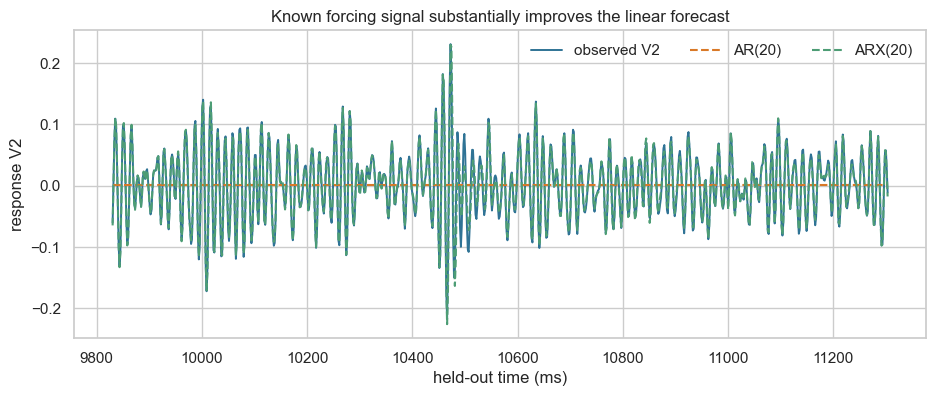

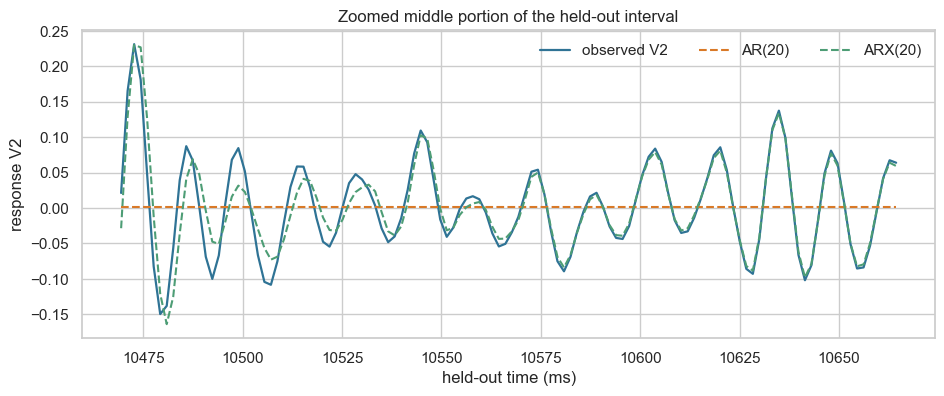

In [6]:
arx_scaler, arx_model = fit_linear_forecaster(
    input_signal=u_train,
    output_signal=y_train,
    order=ORDER,
    include_input=True,
)
arx_prediction = recursive_linear_forecast(
    input_signal=u_test,
    observed_output=y_test,
    order=ORDER,
    include_input=True,
    scaler=arx_scaler,
    model=arx_model,
)
arx_rmse = rmse(actual=y_test, predicted=arx_prediction, warmup=ORDER)
print(f"ARX({ORDER}) recursive multi-step held-out RMSE: {arx_rmse:.5f}")

window_start = 6_000
window_length = 900
window = slice(window_start, window_start + window_length)
window_time = np.arange(window_start, window_start + window_length) * sampling_time * 1_000

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(window_time, y_test[window], color="#2f7395", linewidth=1.4, label="observed V2")
ax.plot(window_time, ar_prediction[window], color="#d97927", linestyle="--", label="AR(20)")
ax.plot(window_time, arx_prediction[window], color="#4d9d75", linestyle="--", label="ARX(20)")
ax.set(xlabel="held-out time (ms)", ylabel="response V2", title="Known forcing signal substantially improves the linear forecast")
ax.legend(frameon=False, ncol=3)
plt.show()

# Inspect the middle of the displayed interval on a tighter time scale.
zoom_window_start = window_start + window_length // 2 - 60
zoom_window_length = 120
zoom_window = slice(zoom_window_start, zoom_window_start + zoom_window_length)
zoom_time = np.arange(zoom_window_start, zoom_window_start + zoom_window_length) * sampling_time * 1_000

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(zoom_time, y_test[zoom_window], color="#2f7395", linewidth=1.6, label="observed V2")
ax.plot(zoom_time, ar_prediction[zoom_window], color="#d97927", linestyle="--", label="AR(20)")
ax.plot(zoom_time, arx_prediction[zoom_window], color="#4d9d75", linestyle="--", label="ARX(20)")
ax.set(
    xlabel="held-out time (ms)",
    ylabel="response V2",
    title="Zoomed middle portion of the held-out interval",
)
ax.legend(frameon=False, ncol=3)
plt.show()

## 5. Learn a nonlinear state with a small RNN

A **recurrent neural network (RNN)** extends the MLP idea to sequential data. An MLP applies a learned transformation once to one fixed input vector. An RNN instead applies the **same small learned transformation** repeatedly as it moves through a sequence.

At time $t$, the RNN combines the current known input $u_t$, the preceding response $y_{t-1}$, and its previous hidden state $\mathbf{h}_{t-1}$. The hidden state is a learned vector of internal memory: it is not a measured physical state, but it can summarize useful information from earlier positions in the sequence. A separate readout function $f$ maps the resulting state to the next-response prediction.

We use $\tanh$ as the hidden-state activation. It is smooth, keeps each hidden-state value between $-1$ and $1$, and preserves positive and negative values. Those bounded values are useful when the update is repeated through a sequence. `tanh` is a modeling choice, not the only possible activation.

$$
\mathbf{h}_t = \tanh(W_h \mathbf{h}_{t-1} + W_y y_{t-1} + W_u u_t + b_h),
\qquad \widehat{y}_t = f(\mathbf{h}_t).
$$

For a transparent comparison with ARX(20), each prediction below rebuilds the RNN's hidden state from a recent 20-sample window. During the recursive multi-step test forecast, those windows contain past **predicted** responses after initialization.

In [7]:
class RecurrentPredictor(torch.nn.Module):
    """Map a recent input--response sequence to the next response.

    Args:
        hidden_size: Number of values carried by the learned recurrent state.
    """

    def __init__(self, *, hidden_size: int) -> None:
        super().__init__()
        self.rnn = torch.nn.RNN(
            input_size=2,  # [known input, previous response]
            hidden_size=hidden_size,
            batch_first=True,
            nonlinearity="tanh",
        )
        self.readout = torch.nn.Sequential(
            torch.nn.Linear(hidden_size, hidden_size),
            torch.nn.Tanh(),
            torch.nn.Linear(hidden_size, 1),
        )

    def forward(self, sequence: torch.Tensor) -> torch.Tensor:
        """Predict one next standardized response for each sequence.

        Args:
            sequence: Tensor of shape `(batch, time, 2)`.

        Returns:
            A length-`batch` vector of standardized next-response predictions.
        """
        hidden_values, _ = self.rnn(sequence)
        return self.readout(hidden_values[:, -1, :]).squeeze(-1)


def make_sequence_windows(
    *,
    input_signal: np.ndarray,
    output_signal: np.ndarray,
    order: int,
) -> tuple[np.ndarray, np.ndarray]:
    """Create `[input, previous response]` sequence windows and next targets.

    Args:
        input_signal: Standardized known forcing signal.
        output_signal: Standardized response signal.
        order: Number of sequence positions in every input window.

    Returns:
        A sequence tensor with shape `(samples, order, 2)` and a target vector.
    """
    sequences: list[np.ndarray] = []
    targets: list[float] = []
    for index in range(order, len(output_signal)):
        positions = np.arange(index - order + 1, index + 1)
        sequences.append(
            np.column_stack((input_signal[positions], output_signal[positions - 1]))
        )
        targets.append(output_signal[index])
    return np.asarray(sequences, dtype=np.float32), np.asarray(targets, dtype=np.float32)


def train_sequence_model(
    *,
    model: torch.nn.Module,
    sequences: np.ndarray,
    targets: np.ndarray,
    epochs: int,
    batch_size: int,
    batches_per_epoch: int,
) -> list[float]:
    """Train an RNN or LSTM with the same sampled mini-batches.

    Args:
        model: Sequence model whose output is one standardized response.
        sequences: Training tensor with shape `(samples, time, 2)`.
        targets: Standardized next-response targets.
        epochs: Number of passes through sampled mini-batches.
        batch_size: Number of sequences per mini-batch.
        batches_per_epoch: Number of mini-batches sampled in each epoch.

    Returns:
        The mean mini-batch MSE after each epoch.
    """
    optimizer = torch.optim.Adam(model.parameters(), lr=0.003, weight_decay=1e-5)
    loss_function = torch.nn.MSELoss()
    generator = np.random.default_rng(RANDOM_SEED)
    training_losses: list[float] = []

    for _ in range(epochs):
        model.train()
        batch_losses: list[float] = []
        for _ in range(batches_per_epoch):
            chosen_rows = generator.integers(0, len(sequences), size=batch_size)
            sequence_batch = torch.from_numpy(sequences[chosen_rows]).to(device)
            target_batch = torch.from_numpy(targets[chosen_rows]).to(device)

            optimizer.zero_grad()  # PyTorch otherwise accumulates gradients from earlier batches.
            prediction_batch = model(sequence_batch)
            loss = loss_function(prediction_batch, target_batch)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            batch_losses.append(loss.item())
        training_losses.append(float(np.mean(batch_losses)))

    return training_losses


def recursive_sequence_forecast(
    *,
    model: torch.nn.Module,
    input_signal: np.ndarray,
    observed_output: np.ndarray,
    order: int,
    input_mean: float,
    input_std: float,
    output_mean: float,
    output_std: float,
) -> np.ndarray:
    """Make a recursive multi-step forecast using only known forcing values.

    Args:
        model: Trained RNN or LSTM that predicts standardized responses.
        input_signal: Known held-out forcing signal.
        observed_output: Held-out response; only the first `order` values initialize history.
        order: Length of each sequence input window.
        input_mean: Training-input mean.
        input_std: Training-input standard deviation.
        output_mean: Training-output mean.
        output_std: Training-output standard deviation.

    Returns:
        Recursive predictions aligned with the held-out response.
    """
    history = list(observed_output[:order])
    predictions = np.full(len(observed_output), np.nan)
    model.eval()
    with torch.no_grad():
        for index in range(order, len(observed_output)):
            positions = np.arange(index - order + 1, index + 1)
            previous_responses = np.asarray([history[position - 1] for position in positions])
            sequence = np.column_stack((
                (input_signal[positions] - input_mean) / input_std,
                (previous_responses - output_mean) / output_std,
            )).astype(np.float32)
            tensor = torch.from_numpy(sequence[None, ...]).to(device)
            standardized_prediction = model(tensor).item()
            prediction = standardized_prediction * output_std + output_mean
            history.append(prediction)
            predictions[index] = prediction
    return predictions

In [8]:
# Standardization statistics are learned from the training experiment only.
# We write the transform explicitly because V1 and V2 are each one-dimensional signals,
# and these four scalars are reused inside the recursive forecast below. `StandardScaler`
# would give the same result, but would require repeated two-dimensional reshaping here.
u_mean, u_std = float(u_train.mean()), float(u_train.std())
y_mean, y_std = float(y_train.mean()), float(y_train.std())
u_train_scaled = (u_train - u_mean) / u_std
y_train_scaled = (y_train - y_mean) / y_std
train_sequences, train_targets = make_sequence_windows(
    input_signal=u_train_scaled,
    output_signal=y_train_scaled,
    order=ORDER,
)

HIDDEN_SIZE = 16
EPOCHS = 100
BATCH_SIZE = 128
BATCHES_PER_EPOCH = 32

# The RNN and LSTM below use the same training budget and sampled mini-batches.
torch.manual_seed(RANDOM_SEED)
rnn_model = RecurrentPredictor(hidden_size=HIDDEN_SIZE).to(device)
rnn_training_losses = train_sequence_model(
    model=rnn_model,
    sequences=train_sequences,
    targets=train_targets,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    batches_per_epoch=BATCHES_PER_EPOCH,
)

for epoch in range(20, EPOCHS + 1, 20):
    print(f"RNN epoch {epoch:>3}: mean batch MSE = {rnn_training_losses[epoch - 1]:.5f}")

RNN epoch  20: mean batch MSE = 0.00046
RNN epoch  40: mean batch MSE = 0.00029
RNN epoch  60: mean batch MSE = 0.00019
RNN epoch  80: mean batch MSE = 0.00014
RNN epoch 100: mean batch MSE = 0.00006


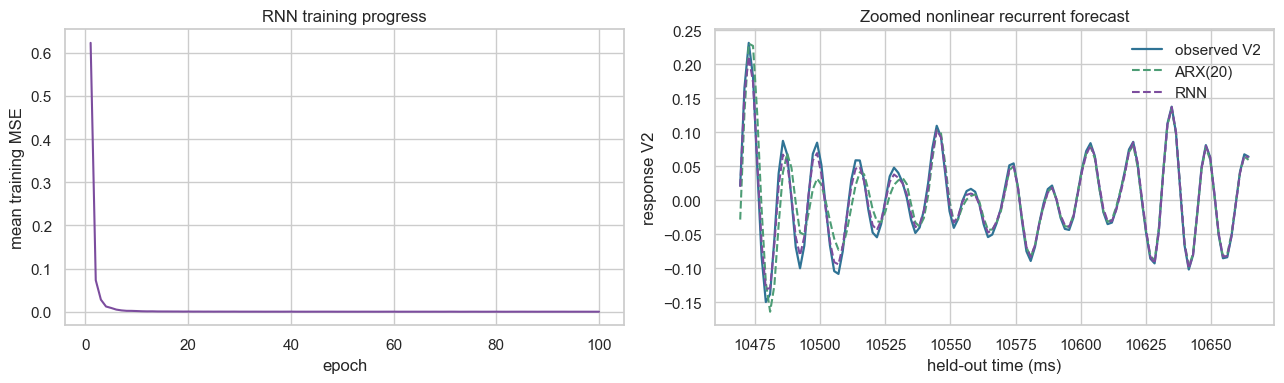

RNN recursive multi-step held-out RMSE: 0.00193


In [9]:
rnn_prediction = recursive_sequence_forecast(
    model=rnn_model,
    input_signal=u_test,
    observed_output=y_test,
    order=ORDER,
    input_mean=u_mean,
    input_std=u_std,
    output_mean=y_mean,
    output_std=y_std,
)
rnn_rmse = rmse(actual=y_test, predicted=rnn_prediction, warmup=ORDER)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(np.arange(1, EPOCHS + 1), rnn_training_losses, color="#7c4d9e")
axes[0].set(xlabel="epoch", ylabel="mean training MSE", title="RNN training progress")
axes[1].plot(zoom_time, y_test[zoom_window], color="#2f7395", linewidth=1.6, label="observed V2")
axes[1].plot(zoom_time, arx_prediction[zoom_window], color="#4d9d75", linestyle="--", label="ARX(20)")
axes[1].plot(zoom_time, rnn_prediction[zoom_window], color="#7c4d9e", linestyle="--", label="RNN")
axes[1].set(xlabel="held-out time (ms)", ylabel="response V2", title="Zoomed nonlinear recurrent forecast")
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

print(f"RNN recursive multi-step held-out RMSE: {rnn_rmse:.5f}")

## 6. (Optional) Compare the small RNN with an LSTM

An **LSTM (long short-term memory)** network is another recurrent architecture. Like the RNN above, it reads the same input--response sequence and produces one next-response prediction. Its gates control what information is stored, forgotten, and exposed through a separate cell state.

To isolate the architectural change, the comparison below keeps the 20-sample sequence, 16 hidden values, optimizer, learning rate, epochs, mini-batches, and recursive held-out protocol fixed. The LSTM has more learned values because its gates add parameters, so this is a controlled illustration—not a claim of equal model capacity or a guarantee that an LSTM will always win.

In [10]:
class LSTMPredictor(torch.nn.Module):
    """Map a recent input--response sequence to the next response with an LSTM.

    Args:
        hidden_size: Number of values in the hidden and cell states.
    """

    def __init__(self, *, hidden_size: int) -> None:
        super().__init__()
        self.lstm = torch.nn.LSTM(
            input_size=2,  # [known input, previous response]
            hidden_size=hidden_size,
            batch_first=True,
        )
        self.readout = torch.nn.Sequential(
            torch.nn.Linear(hidden_size, hidden_size),
            torch.nn.Tanh(),
            torch.nn.Linear(hidden_size, 1),
        )

    def forward(self, sequence: torch.Tensor) -> torch.Tensor:
        """Predict one next standardized response for each sequence."""
        hidden_values, _ = self.lstm(sequence)
        return self.readout(hidden_values[:, -1, :]).squeeze(-1)

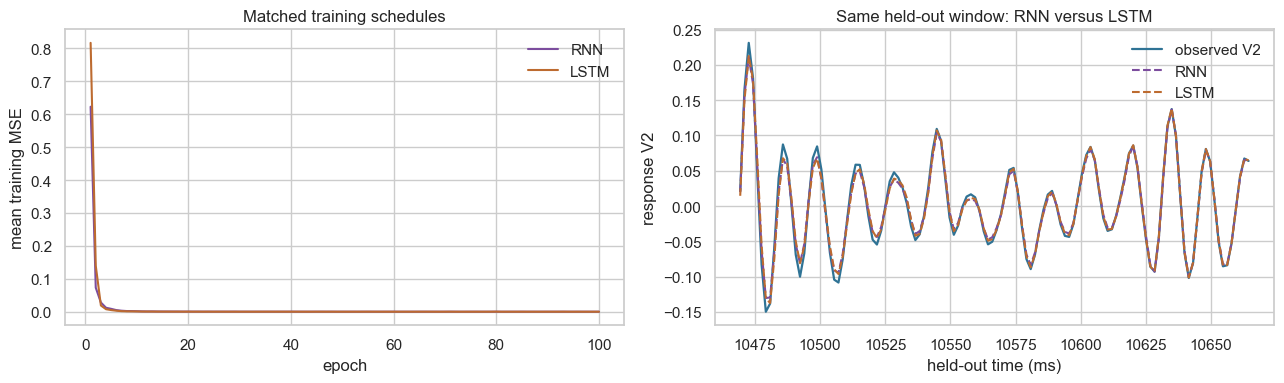

,model,information available,recursive multi-step held-out RMSE
0,AR(20),past response only,0.05429
1,ARX(20),past response + known forcing input,0.00694
2,small RNN,recent input--response sequence + learned nonlinear state,0.00193
3,small LSTM,same sequence + gated hidden and cell states,0.00164


In [11]:
# Use the same random seed, data windows, and sampled mini-batches as the RNN.
torch.manual_seed(RANDOM_SEED)
lstm_model = LSTMPredictor(hidden_size=HIDDEN_SIZE).to(device)
lstm_training_losses = train_sequence_model(
    model=lstm_model,
    sequences=train_sequences,
    targets=train_targets,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    batches_per_epoch=BATCHES_PER_EPOCH,
)

lstm_prediction = recursive_sequence_forecast(
    model=lstm_model,
    input_signal=u_test,
    observed_output=y_test,
    order=ORDER,
    input_mean=u_mean,
    input_std=u_std,
    output_mean=y_mean,
    output_std=y_std,
)
lstm_rmse = rmse(actual=y_test, predicted=lstm_prediction, warmup=ORDER)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(np.arange(1, EPOCHS + 1), rnn_training_losses, color="#7c4d9e", label="RNN")
axes[0].plot(np.arange(1, EPOCHS + 1), lstm_training_losses, color="#bd6b30", label="LSTM")
axes[0].set(xlabel="epoch", ylabel="mean training MSE", title="Matched training schedules")
axes[0].legend(frameon=False)

axes[1].plot(zoom_time, y_test[zoom_window], color="#2f7395", linewidth=1.6, label="observed V2")
axes[1].plot(zoom_time, rnn_prediction[zoom_window], color="#7c4d9e", linestyle="--", label="RNN")
axes[1].plot(zoom_time, lstm_prediction[zoom_window], color="#bd6b30", linestyle="--", label="LSTM")
axes[1].set(xlabel="held-out time (ms)", ylabel="response V2", title="Same held-out window: RNN versus LSTM")
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

comparison = pd.DataFrame({
    "model": [f"AR({ORDER})", f"ARX({ORDER})", "small RNN", "small LSTM"],
    "information available": [
        "past response only",
        "past response + known forcing input",
        "recent input--response sequence + learned nonlinear state",
        "same sequence + gated hidden and cell states",
    ],
    "recursive multi-step held-out RMSE": [ar_rmse, arx_rmse, rnn_rmse, lstm_rmse],
})
display(comparison.style.format({"recursive multi-step held-out RMSE": "{:.5f}"}))

## 7. What this comparison does—and does not—show

- Adding `V1` helps because it is a known causal input that drives the system; AR cannot react to it directly.
- The RNN can learn nonlinear effects in a recent history, which is useful for this Duffing-like system.
- The LSTM adds gates that can preserve useful information, but it does **not** guarantee lower held-out error; its result here depends on this data and training configuration. Both models rebuild from a 20-sample window at each forecasting time, so this does not test arbitrarily long-term memory.
- The fair comparison is always on future or held-out experiments, with only information available at the forecasting time.
- A nonlinear fixed-window model, a different recurrent architecture, or a different input horizon could also improve this task.

<p style="margin-top: 1.5rem;"><a href="index.html">← Return to Sequential models</a></p>